# Source audit: historical stocks and ETFs

This notebook analyzes the complete supplied archive audit: every file and every parsed observation, with duplicated directory trees counted once. It contains data-quality findings, not strategy results.

Reproduce the audit with `quantlab audit --archive data/raw/archive.zip --output data/interim/source-audit`. Set `QUANT_AUDIT_DIR` if the completed audit is stored elsewhere. Raw prices and the archive remain outside Git.

In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
AUDIT = Path(os.environ.get("QUANT_AUDIT_DIR", ROOT / "data/interim/source-audit"))
ARCHIVE_SHA256 = "d9317c8fb2d63b9b00db5f933b6c9639d2bf7ea3b918169bb5cec5903dce85a1"
FILE_AUDIT_SHA256 = "aa2df601ae2575959117d07b111563ca84bcc7b20b2fe3b0198589ea77e3c66b"
file_bytes = (AUDIT / "file-summaries.json").read_bytes()
assert hashlib.sha256(file_bytes).hexdigest() == FILE_AUDIT_SHA256
summary = json.loads((AUDIT / "audit-summary.json").read_bytes())
files = pd.DataFrame(json.loads(file_bytes))
assert summary["source_sha256"] == ARCHIVE_SHA256
assert summary["all_mirrors_byte_identical"] is True
assert len(files) == 8539 and int(files["rows"].sum()) == 17453243
assert not summary["unsafe_members"] and not summary["encrypted_members"]
assert not summary["repeated_member_names"]
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"Verified {len(files):,} unique files and {int(files['rows'].sum()):,} real observations.")

Verified 8,539 unique files and 17,453,243 real observations.


## Population and duplicate trees

The archive contains a root tree and a `Data/` tree. The audit compared the bytes of all 8,539 mirror pairs; treating them as separate assets would double the population. A source symbol is a file identifier, not a verified permanent security identifier.

,files,rows
asset_type,,
ETFs,1344,2565578
Stocks,7195,14887665


,archive_members,unique_files,empty_files,first_observation,last_observation
0,17078,8539,32,1962-01-02,2017-11-10


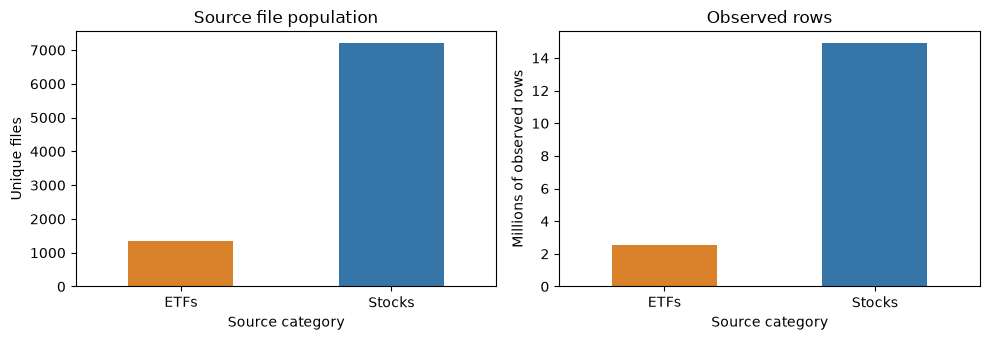

In [2]:
population = files.groupby("asset_type").agg(files=("path", "size"), rows=("rows", "sum"))
display(population)
display(pd.DataFrame([{"archive_members": summary["total_members"], "unique_files": len(files), "empty_files": int((files["rows"] == 0).sum()), "first_observation": summary["earliest_date"], "last_observation": summary["latest_date"]}]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
population["files"].plot.bar(ax=axes[0], color=["#d9822b", "#3575a8"], rot=0)
population["rows"].div(1e6).plot.bar(ax=axes[1], color=["#d9822b", "#3575a8"], rot=0)
axes[0].set(xlabel="Source category", ylabel="Unique files", title="Source file population")
axes[1].set(xlabel="Source category", ylabel="Millions of observed rows", title="Observed rows")
fig.tight_layout()
fig.savefig(FIGURES / "source-population.png", dpi=160)
plt.show()

## Observed endpoints

These distributions show each nonempty file's first and last observed year. An endpoint is not a verified listing or delisting event. The source does not supply historical membership, corporate-action outcomes, or a security master. The archive endpoint is November 10, 2017.

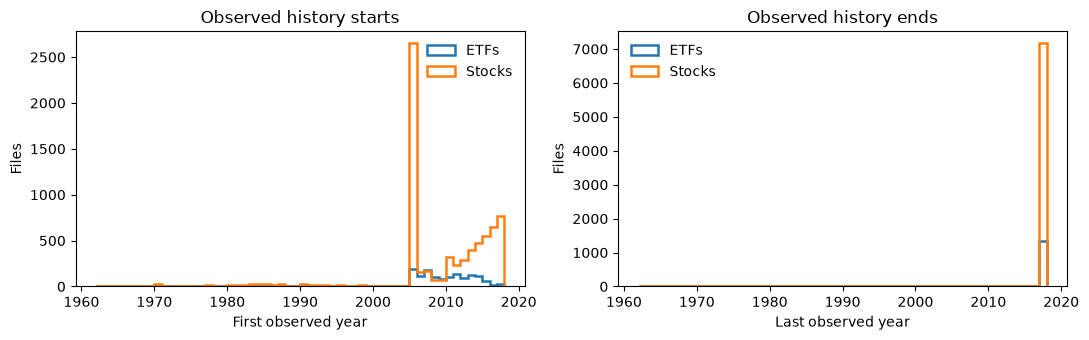

482 nonempty files end before the common archive endpoint; their economic outcomes are not inferred.


In [3]:
nonempty = files.loc[files["rows"] > 0].copy()
nonempty["first_year"] = pd.to_datetime(nonempty["first_date"]).dt.year
nonempty["last_year"] = pd.to_datetime(nonempty["last_date"]).dt.year
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for category, group in nonempty.groupby("asset_type"):
    axes[0].hist(group["first_year"], bins=range(1962, 2019), histtype="step", linewidth=1.8, label=category)
    axes[1].hist(group["last_year"], bins=range(1962, 2019), histtype="step", linewidth=1.8, label=category)
axes[0].set(xlabel="First observed year", ylabel="Files", title="Observed history starts")
axes[1].set(xlabel="Last observed year", ylabel="Files", title="Observed history ends")
for axis in axes: axis.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "source-endpoints.png", dpi=160)
plt.show()
early_end = int((nonempty["last_date"] < summary["latest_date"]).sum())
print(f"{early_end:,} nonempty files end before the common archive endpoint; their economic outcomes are not inferred.")

## Findings to preserve

The following counts are observed findings. Categories can overlap and must not be summed into an exclusion count. Nonpositive marks cannot support a tradable-price return; an inconsistent high or low requires field-specific investigation. No price is replaced, interpolated or removed here. Weekend dates will be checked against the declared exchange-calendar mapping during normalization.

,Observed rows
Inconsistent OHLC rows,109
Negative-price rows,1
Zero-price rows,53
Zero-volume rows,27697
Weekend rows,45


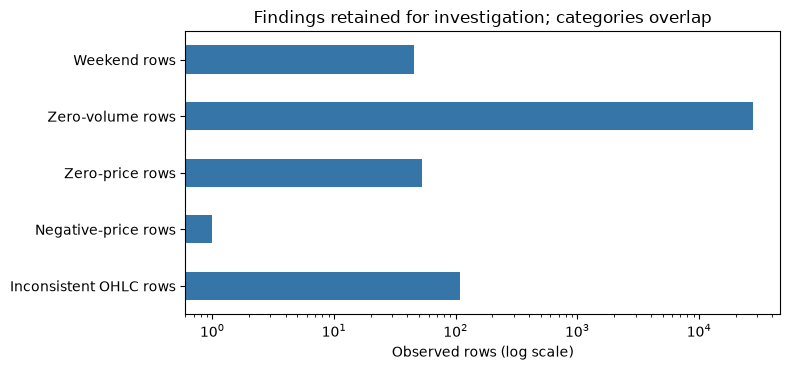

In [4]:
findings = pd.Series({
    "Inconsistent OHLC rows": summary["issue_totals"].get("ohlc_inconsistent", 0),
    "Negative-price rows": summary["issue_totals"].get("negative_price", 0),
    "Zero-price rows": summary["zero_price_rows"],
    "Zero-volume rows": summary["zero_volume_rows"],
    "Weekend rows": summary["weekend_rows"],
}, name="Observed rows")
display(findings.to_frame())
fig, axis = plt.subplots(figsize=(8, 3.8))
findings.plot.barh(ax=axis, color="#3575a8", logx=True)
axis.set(xlabel="Observed rows (log scale)", ylabel="", title="Findings retained for investigation; categories overlap")
fig.tight_layout()
fig.savefig(FIGURES / "source-quality-findings.png", dpi=160)
plt.show()

## Research interpretation

The publisher describes the prices as split/dividend adjusted. The supplied files do not include adjustment factors, corporate actions, dividends, or delisting returns, so that statement remains a provider claim. Volume adjustment and execution capacity are not established. Daily opening prices are research proxies rather than observed auction fills.

The three studies will share explicit calendars, information cutoffs, missing-outcome policies, and a final evaluation freeze. A source audit does not establish alpha, historical investability, or model quality.

In [5]:
result = {
    "schema": "full_real_archive_notebook_analysis_v1",
    "archive_sha256": ARCHIVE_SHA256,
    "file_audit_sha256": FILE_AUDIT_SHA256,
    "unique_files": len(files),
    "observed_rows": int(files["rows"].sum()),
    "empty_files": int((files["rows"] == 0).sum()),
    "early_endpoint_files": early_end,
    "findings": {key: int(value) for key, value in findings.items()},
    "real_data_only": True,
    "strategy_performance_evaluated": False,
    "plots": ["source-population.png", "source-endpoints.png", "source-quality-findings.png"],
}
(ROOT / "reports/source-audit-analysis.json").write_text(json.dumps(result, indent=2) + "\n", encoding="utf-8")
display(pd.DataFrame([{"status": "Full source audit analyzed", "model_training": "Not performed", "strategy_result": "Not evaluated"}]))

,status,model_training,strategy_result
0,Full source audit analyzed,Not performed,Not evaluated
